# Figure S5C — Peak GPU memory

Peak device memory used by metapredict V1, V2 and V3 while predicting the human reference proteome on each GPU.

**How it is made.** GPU runs from `data/benchmarks/proteome/` (metapredict 3.1.0 at its default per-device batch size: 256 on CUDA, 512 on MPS). CUDA memory is `torch.cuda.max_memory_allocated` over the timed region; MPS memory is the largest sampled `torch.mps.driver_allocated_memory`. GB here is 2$^{30}$ bytes.

**Output:** `figures/figure_S05C.pdf`

In [1]:
import matplotlib.pyplot as plt

from figtools import apply_style, save_panel
from perf_plots import (grouped_version_bars, hardware_groups, hardware_label, median_by,
                        proteome_rows, version_legend)

apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [2]:
gpu_rows = [r for r in proteome_rows() if r['device_used'] != 'cpu']
assert gpu_rows, 'no GPU runs in data/benchmarks/proteome/'
groups = hardware_groups(gpu_rows)
peak_gpu_gb = median_by(gpu_rows, lambda r: (r['network_version'], hardware_label(r)), 'peak_gpu_gb')

proteome: 12 rows from 12 files; metapredict (version, commit): [('3.1.0+6.ga1b28a7.dirty', '7dcf52c+dirty'), ('3.1.0+7.g7dcf52c.dirty', '7dcf52c+dirty')]


Wrote figures/figure_S05C.pdf


PosixPath('figures/figure_S05C.pdf')

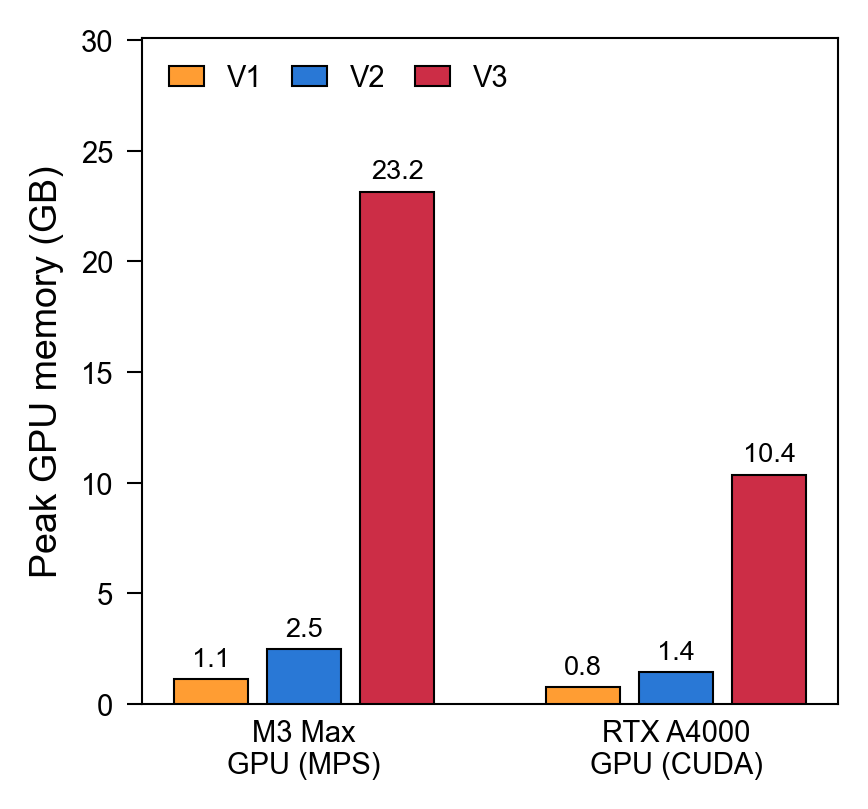

In [3]:
fig, ax = plt.subplots(figsize=(3.0, 2.8), dpi=150)
grouped_version_bars(ax, groups, peak_gpu_gb, label_fmt=lambda v: f'{v:.1f}')
ax.set_ylim(0, max(peak_gpu_gb.values()) * 1.3)
ax.set_ylabel('Peak GPU memory (GB)', fontsize=9)
version_legend(ax, loc='upper left', ncol=3)
plt.tight_layout()
save_panel(fig, 'figure_S05C')